In [1]:
import os
import pandas as pd

In [3]:
path = r'C:\Users\luyer\NN_box_office_revenue\data\tmdb-box-office-prediction'
train_path = os.path.join(path, 'train.csv')
data_train = pd.read_csv(train_path)

In [4]:
test_path = os.path.join(path, 'test.csv')
data_test = pd.read_csv(test_path)

Matplotlib is building the font cache; this may take a moment.


<Axes: >

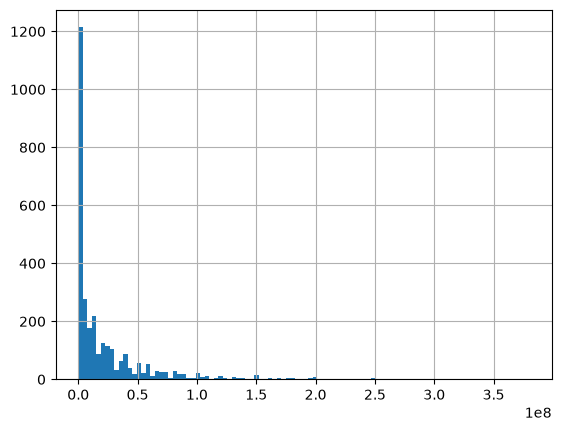

In [7]:
data_train.budget.dropna().hist(bins=100)

In [8]:
data_train.columns

Index(['id', 'belongs_to_collection', 'budget', 'genres', 'homepage',
       'imdb_id', 'original_language', 'original_title', 'overview',
       'popularity', 'poster_path', 'production_companies',
       'production_countries', 'release_date', 'runtime', 'spoken_languages',
       'status', 'tagline', 'title', 'Keywords', 'cast', 'crew', 'revenue'],
      dtype='str')

In [9]:
def has_value(series):
    return series.notna() & series.astype("string").str.strip().ne("")


for dataframe in [data_train, data_test]:
    dataframe["has_belongs_to_collection"] = has_value(dataframe["belongs_to_collection"]).astype(int)
    dataframe["has_homepage"] = has_value(dataframe["homepage"]).astype(int)


data_train[["belongs_to_collection", "has_belongs_to_collection", "homepage", "has_homepage"]].head()

,belongs_to_collection,has_belongs_to_collection,homepage,has_homepage
0,"[{'id': 313576, 'name': 'Hot Tub Time Machine ...",1,NaN,0
1,"[{'id': 107674, 'name': 'The Princess Diaries ...",1,NaN,0
2,NaN,0,http://sonyclassics.com/whiplash/,1
3,NaN,0,http://kahaanithefilm.com/,1
4,NaN,0,NaN,0


In [10]:
import numpy as np


for dataframe in [data_train, data_test]:
    for column in ["budget", "revenue"]:
        if column in dataframe.columns:
            numeric_values = pd.to_numeric(dataframe[column], errors="coerce")
            dataframe[f"log_{column}"] = np.log1p(numeric_values)


data_train[["budget", "log_budget", "revenue", "log_revenue"]].head()

,budget,log_budget,revenue,log_revenue
0,14000000,16.454568,12314651,16.326300
1,40000000,17.504390,95149435,18.370959
2,3300000,15.009433,13092000,16.387512
3,1200000,13.997833,16000000,16.588099
4,0,0.000000,3923970,15.182615


In [11]:
import ast
import re


def extract_genres(value):
    if not isinstance(value, str) or not value.strip():
        return []

    try:
        records = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return []

    return [
        record["name"]
        for record in records
        if isinstance(record, dict) and record.get("name")
    ]


def genre_column_name(genre):
    normalized = re.sub(r"[^a-z0-9]+", "_", genre.lower()).strip("_")
    return f"genre_{normalized}"


train_genres = data_train["genres"].map(extract_genres)
test_genres = data_test["genres"].map(extract_genres)
all_genres = sorted({genre for genres in train_genres for genre in genres} | {genre for genres in test_genres for genre in genres})
genre_columns = [genre_column_name(genre) for genre in all_genres]

for dataframe, genre_lists in [(data_train, train_genres), (data_test, test_genres)]:
    existing_genre_columns = [column for column in dataframe.columns if column.startswith("genre_")]
    dataframe.drop(columns=existing_genre_columns, inplace=True)
    genre_features = pd.DataFrame(
        {
            genre_column_name(genre): genre_lists.map(
                lambda genres, current_genre=genre: int(current_genre in genres)
            )
            for genre in all_genres
        },
        index=dataframe.index,
    )
    dataframe[genre_columns] = genre_features

print(f"Created {len(all_genres)} genre columns: {all_genres}")
data_train[genre_columns].head()

Created 20 genre columns: ['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'Foreign', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']


,genre_action,genre_adventure,genre_animation,genre_comedy,genre_crime,genre_documentary,genre_drama,genre_family,genre_fantasy,genre_foreign,genre_history,genre_horror,genre_music,genre_mystery,genre_romance,genre_science_fiction,genre_tv_movie,genre_thriller,genre_war,genre_western
0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


<Axes: title={'center': 'Top 10 Original Languages'}, xlabel='original_language'>

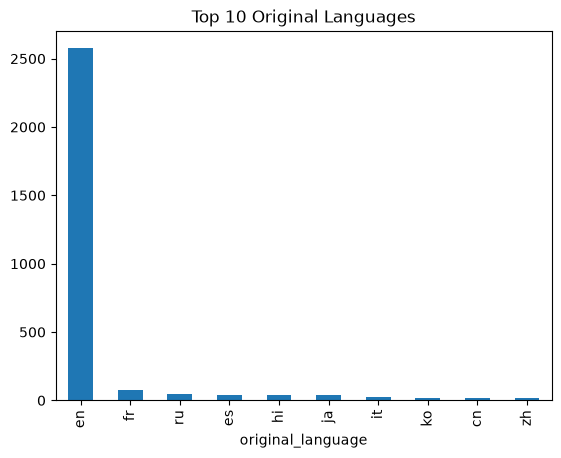

In [12]:
data_train.original_language.value_counts().head(10).plot(kind="bar", title="Top 10 Original Languages")

In [13]:
language_values = pd.concat(
    [data_train["original_language"], data_test["original_language"]],
).astype("string").str.strip()

language_counts = language_values.dropna().value_counts()
top_10_languages = language_counts.head(10).index.tolist()
language_columns = [f"original_language_{language}" for language in top_10_languages]
language_columns.append("original_language_others")

for dataframe in [data_train, data_test]:
    existing_language_columns = [
        column for column in dataframe.columns
        if column.startswith("original_language_")
    ]
    dataframe.drop(columns=existing_language_columns, inplace=True)

    values = dataframe["original_language"].astype("string").str.strip()
    language_features = pd.DataFrame(
        {
            f"original_language_{language}": (values == language).astype(int)
            for language in top_10_languages
        },
        index=dataframe.index,
    )
    language_features["original_language_others"] = (
        values.isna() | ~values.isin(top_10_languages)
    ).astype(int)
    dataframe[language_columns] = language_features

print(f"Top 10 languages: {top_10_languages}")
data_train[language_columns].head()

Top 10 languages: ['en', 'fr', 'hi', 'ru', 'es', 'ja', 'it', 'ko', 'de', 'zh']


,original_language_en,original_language_fr,original_language_hi,original_language_ru,original_language_es,original_language_ja,original_language_it,original_language_ko,original_language_de,original_language_zh,original_language_others
0,1,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,1,0,0,0


In [17]:
import ast


def extract_company_names(value):
    if not isinstance(value, str) or not value.strip():
        return []

    try:
        records = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return []

    return {
        record["name"]
        for record in records
        if isinstance(record, dict) and record.get("name")
    }


production_company_lists = pd.concat(
    [data_train["production_companies"], data_test["production_companies"]],
).map(extract_company_names)

top_10_production_companies = (
    production_company_lists.explode().dropna().value_counts().head(40)
)
top_10_production_companies

production_companies
Warner Bros.                              491
Universal Pictures                        463
Paramount Pictures                        393
Twentieth Century Fox Film Corporation    341
Columbia Pictures                         236
Metro-Goldwyn-Mayer (MGM)                 207
New Line Cinema                           198
Touchstone Pictures                       158
Walt Disney Pictures                      147
Columbia Pictures Corporation             140
Canal+                                    130
TriStar Pictures                          121
Relativity Media                          115
United Artists                            105
Miramax Films                             104
Village Roadshow Pictures                  89
Regency Enterprises                        81
DreamWorks SKG                             78
Fox Searchlight Pictures                   69
Amblin Entertainment                       68
Lionsgate                                  68
StudioCanal  

In [18]:
top_40_production_companies = top_10_production_companies.head(40).index.tolist()


def production_company_column_name(company):
    normalized = re.sub(r"[^a-z0-9]+", "_", company.lower()).strip("_")
    return f"production_company_{normalized}"


production_company_columns = [
    production_company_column_name(company)
    for company in top_40_production_companies
]
production_company_columns.append("production_company_others")

for dataframe in [data_train, data_test]:
    existing_company_columns = [
        column for column in dataframe.columns
        if column.startswith("production_company_")
    ]
    dataframe.drop(columns=existing_company_columns, inplace=True)

    company_lists = dataframe["production_companies"].map(extract_company_names)
    company_features = pd.DataFrame(
        {
            production_company_column_name(company): company_lists.map(
                lambda companies, current_company=company: int(current_company in companies)
            )
            for company in top_40_production_companies
        },
        index=dataframe.index,
    )
    company_features["production_company_others"] = company_lists.map(
        lambda companies: int(not companies or not set(companies).intersection(top_40_production_companies))
    )
    dataframe[production_company_columns] = company_features

print(f"Created {len(production_company_columns)} production-company columns")
data_train[production_company_columns].head()

Created 41 production-company columns


,production_company_warner_bros,production_company_universal_pictures,production_company_paramount_pictures,production_company_twentieth_century_fox_film_corporation,production_company_columbia_pictures,production_company_metro_goldwyn_mayer_mgm,production_company_new_line_cinema,production_company_touchstone_pictures,production_company_walt_disney_pictures,production_company_columbia_pictures_corporation,...,production_company_imagine_entertainment,production_company_new_regency_pictures,production_company_focus_features,production_company_castle_rock_entertainment,production_company_the_weinstein_company,production_company_silver_pictures,production_company_lions_gate_films,production_company_legendary_pictures,production_company_morgan_creek_productions,production_company_others
0,0,0,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [20]:
def extract_country_names(value):
    if not isinstance(value, str) or not value.strip():
        return []

    try:
        records = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return []

    return {
        record["name"]
        for record in records
        if isinstance(record, dict) and record.get("name")
    }


production_country_lists = pd.concat(
    [data_train["production_countries"], data_test["production_countries"]],
).map(extract_country_names)

top_10_production_countries = (
    production_country_lists.explode().dropna().value_counts().head(20)
)
top_10_production_countries

production_countries
United States of America    5617
United Kingdom               917
France                       570
Germany                      411
Canada                       323
India                        220
Italy                        160
Japan                        157
Australia                    148
Spain                        139
Russia                       132
China                         99
Hong Kong                     96
Belgium                       64
Ireland                       62
South Korea                   58
Sweden                        50
Mexico                        44
Netherlands                   43
Denmark                       40
Name: count, dtype: int64

In [22]:
top_20_production_countries = (
    production_country_lists.explode().dropna().value_counts().head(20).index.tolist()
)


def production_country_column_name(country):
    normalized = re.sub(r"[^a-z0-9]+", "_", country.lower()).strip("_")
    return f"production_country_{normalized}"


production_country_columns = [
    production_country_column_name(country)
    for country in top_20_production_countries
]
production_country_columns.append("production_country_others")

for dataframe in [data_train, data_test]:
    existing_country_columns = [
        column for column in dataframe.columns
        if column.startswith("production_country_")
    ]
    dataframe.drop(columns=existing_country_columns, inplace=True)

    country_lists = dataframe["production_countries"].map(extract_country_names)
    country_features = pd.DataFrame(
        {
            production_country_column_name(country): country_lists.map(
                lambda countries, current_country=country: int(current_country in countries)
            )
            for country in top_20_production_countries
        },
        index=dataframe.index,
    )
    country_features["production_country_others"] = country_lists.map(
        lambda countries: int(
            not countries
            or not set(countries).intersection(top_20_production_countries)
        )
    )
    dataframe[production_country_columns] = country_features

print(f"Created {len(production_country_columns)} production-country columns")
data_train[production_country_columns].head()

Created 21 production-country columns


,production_country_united_states_of_america,production_country_united_kingdom,production_country_france,production_country_germany,production_country_canada,production_country_india,production_country_italy,production_country_japan,production_country_australia,production_country_spain,...,production_country_china,production_country_hong_kong,production_country_belgium,production_country_ireland,production_country_south_korea,production_country_sweden,production_country_mexico,production_country_netherlands,production_country_denmark,production_country_others
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [24]:
for dataframe in [data_train, data_test]:
    dataframe["number_of_production_companies"] = dataframe["production_companies"].map(
        lambda value: len(extract_company_names(value))
    )
    dataframe["number_of_production_countries"] = dataframe["production_countries"].map(
        lambda value: len(extract_country_names(value))
    )

    release_dates = pd.to_datetime(
        dataframe["release_date"],
        format="%m/%d/%y",
        errors="coerce",
    )
    dataframe["release_year"] = release_dates.dt.year
    dataframe["release_month"] = release_dates.dt.month


data_train[
    [
        "production_companies",
        "number_of_production_companies",
        "production_countries",
        "number_of_production_countries",
        "release_date",
        "release_year",
        "release_month",
    ]
].head()

,production_companies,number_of_production_companies,production_countries,number_of_production_countries,release_date,release_year,release_month
0,"[{'name': 'Paramount Pictures', 'id': 4}, {'na...",3,"[{'iso_3166_1': 'US', 'name': 'United States o...",1,2/20/15,2015,2
1,"[{'name': 'Walt Disney Pictures', 'id': 2}]",1,"[{'iso_3166_1': 'US', 'name': 'United States o...",1,8/6/04,2004,8
2,"[{'name': 'Bold Films', 'id': 2266}, {'name': ...",3,"[{'iso_3166_1': 'US', 'name': 'United States o...",1,10/10/14,2014,10
3,NaN,0,"[{'iso_3166_1': 'IN', 'name': 'India'}]",1,3/9/12,2012,3
4,NaN,0,"[{'iso_3166_1': 'KR', 'name': 'South Korea'}]",1,2/5/09,2009,2


In [28]:
def extract_cast_value(records, cast_id, field, missing_value):
    matching_records = [record for record in records if record.get("cast_id")                   == cast_id]
    if not matching_records:
        return missing_value

    value = matching_records[0].get(field)
    return missing_value if value is None else value


cast_feature_columns = [
    "cast_1_name",
    "cast_1_gender",
    "cast_2_name",
    "cast_2_gender",
]

for dataframe in [data_train, data_test]:
    cast_lists = dataframe["cast"].map(extract_cast_records)
    dataframe["cast_1_name"] = cast_lists.map(
        lambda records: extract_cast_value(records, 1, "name", "Unknown")
    )
    dataframe["cast_1_gender"] = cast_lists.map(
        lambda records: extract_cast_value(records, 1, "gender", -1)
    ).astype(int)
    dataframe["cast_2_name"] = cast_lists.map(
        lambda records: extract_cast_value(records, 2, "name", "Unknown")
    )
    dataframe["cast_2_gender"] = cast_lists.map(
        lambda records: extract_cast_value(records, 2, "gender", -1)
    ).astype(int)


data_train[cast_feature_columns].head()

,cast_1_name,cast_1_gender,cast_2_name,cast_2_gender
0,Unknown,-1,Unknown,-1
1,Anne Hathaway,1,Julie Andrews,1
2,Unknown,-1,Unknown,-1
3,Vidya Balan,1,Unknown,-1
4,Unknown,-1,Unknown,-1


In [29]:
def get_top_cast_member(records, cast_order, field, missing_value):
    matching_records = [record for record in records if record.get("order") == cast_order]
    if not matching_records:
        return missing_value

    value = matching_records[0].get(field)
    return missing_value if value is None else value


def extract_cast_records(value):
    if not isinstance(value, str) or not value.strip():
        return []

    try:
        records = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return []

    return [record for record in records if isinstance(record, dict)]


cast_feature_columns = [
    "cast_1_name",
    "cast_1_gender",
    "cast_2_name",
    "cast_2_gender",
]

for dataframe in [data_train, data_test]:
    cast_lists = dataframe["cast"].map(extract_cast_records)
    dataframe["cast_1_name"] = cast_lists.map(
        lambda records: get_top_cast_member(records, 0, "name", "Unknown")
    )
    dataframe["cast_1_gender"] = cast_lists.map(
        lambda records: get_top_cast_member(records, 0, "gender", -1)
    ).astype(int)
    dataframe["cast_2_name"] = cast_lists.map(
        lambda records: get_top_cast_member(records, 1, "name", "Unknown")
    )
    dataframe["cast_2_gender"] = cast_lists.map(
        lambda records: get_top_cast_member(records, 1, "gender", -1)
    ).astype(int)

print("Missing top-billed actor values:")
print(data_train[cast_feature_columns].eq("Unknown").sum())
print(data_train[cast_feature_columns].eq(-1).sum())
data_train[cast_feature_columns].head()

Missing top-billed actor values:
cast_1_name      149
cast_1_gender      0
cast_2_name       70
cast_2_gender      0
dtype: int64
cast_1_name        0
cast_1_gender    149
cast_2_name        0
cast_2_gender     70
dtype: int64


,cast_1_name,cast_1_gender,cast_2_name,cast_2_gender
0,Rob Corddry,2,Craig Robinson,2
1,Anne Hathaway,1,Julie Andrews,1
2,Miles Teller,2,J.K. Simmons,2
3,Vidya Balan,1,Nawazuddin Siddiqui,2
4,Kim Kang-woo,2,Jo Jae-hyeon,2


In [31]:
def get_crew_member(records, job, field, missing_value):
    matching_records = [record for record in records if record.get("job") == job]
    if not matching_records:
        return missing_value

    value = matching_records[0].get(field)
    return missing_value if value is None else value


crew_feature_columns = [
    "director_name",
    "director_gender",
    "producer_name",
    "producer_gender",
]

for dataframe in [data_train, data_test]:
    crew_lists = dataframe["crew"].map(extract_cast_records)
    dataframe["director_name"] = crew_lists.map(
        lambda records: get_crew_member(records, "Director", "name", "Unknown")
    )
    dataframe["director_gender"] = crew_lists.map(
        lambda records: get_crew_member(records, "Director", "gender", -1)
    ).astype(int)
    dataframe["producer_name"] = crew_lists.map(
        lambda records: get_crew_member(records, "Producer", "name", "Unknown")
    )
    dataframe["producer_gender"] = crew_lists.map(
        lambda records: get_crew_member(records, "Producer", "gender", -1)
    ).astype(int)

print("Missing crew feature values in training data:")
print(data_train[crew_feature_columns].eq("Unknown").sum())
print(data_train[crew_feature_columns].eq(-1).sum())
data_train[crew_feature_columns].head()

Missing crew feature values in training data:
director_name       16
director_gender      0
producer_name      627
producer_gender      0
dtype: int64
director_name        0
director_gender     16
producer_name        0
producer_gender    627
dtype: int64


,director_name,director_gender,producer_name,producer_gender
0,Steve Pink,2,Andrew Panay,2
1,Garry Marshall,2,Whitney Houston,1
2,Damien Chazelle,2,David Lancaster,2
3,Sujoy Ghosh,0,Sujoy Ghosh,0
4,Jong-seok Yoon,0,Unknown,-1


In [36]:
data_train.head(2).T

,0,1
id,1,2
belongs_to_collection,"[{'id': 313576, 'name': 'Hot Tub Time Machine ...","[{'id': 107674, 'name': 'The Princess Diaries ..."
budget,14000000,40000000
genres,"[{'id': 35, 'name': 'Comedy'}]","[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam..."
homepage,NaN,NaN
imdb_id,tt2637294,tt0368933
original_language,en,en
original_title,Hot Tub Time Machine 2,The Princess Diaries 2: Royal Engagement
overview,"When Lou, who has become the ""father of the In...",Mia Thermopolis is now a college graduate and ...
popularity,6.575393,8.248895


In [35]:
pd.set_option("display.max_rows", None)